# 03 — Extraction routing

## Objective

Turn page features into an explainable choice among native extraction, full OCR, hybrid OCR, and manual review. Then test the decision boundaries and inspect a known failure case.

## Concept

The routing rule is a heuristic, not a learned classifier:

- a page-sized image with no native words suggests full OCR;
- a page-sized image with a small native overlay suggests hybrid OCR;
- native words without a page-sized image suggest native extraction;
- ambiguous pages are sent to review.

The explicit `REVIEW` state is important: uncertainty must not silently become an empty string.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
DOCUMENTS_DIR = PROJECT_ROOT / "data" / "documents"
IMAGE_COVERAGE_THRESHOLD = 0.90
NATIVE_OVERLAY_WORD_LIMIT = 20

## Implementation — observable features

In [2]:
def inspect_page(page):
    words = page.get_text("words")
    images = page.get_image_info()
    page_area = page.rect.get_area()
    coverage = max(
        (
            (pymupdf.Rect(image["bbox"]) & page.rect).get_area() / page_area
            for image in images
        ),
        default=0.0,
    )
    return {
        "native_words": len(words),
        "image_count": len(images),
        "largest_image_fraction": round(coverage, 3),
    }

## Implementation — decision rule

Inputs are a feature dictionary; output is one route label. The two thresholds are named parameters so experiments can change them visibly.

In [3]:
def select_method(
    features,
    image_threshold=IMAGE_COVERAGE_THRESHOLD,
    overlay_word_limit=NATIVE_OVERLAY_WORD_LIMIT,
):
    words = features["native_words"]
    coverage = features["largest_image_fraction"]

    if coverage >= image_threshold:
        if words == 0:
            return "OCR"
        if words < overlay_word_limit:
            return "HYBRID"
        return "REVIEW"
    if words > 0:
        return "NATIVE"
    return "REVIEW"

## Execution — route representative pages

In [4]:
samples = {
    "ch2.pdf": [9, 17, 49, 65],
    "scanned.pdf": [1, 2, 3],
}

routing_rows = []
for filename, page_numbers in samples.items():
    with pymupdf.open(DOCUMENTS_DIR / filename) as document:
        for page_number in page_numbers:
            features = inspect_page(document[page_number - 1])
            routing_rows.append(
                {
                    "page_id": f"{filename} p.{page_number}",
                    **features,
                    "method": select_method(features),
                }
            )

routing_table = pd.DataFrame(routing_rows)
routing_table

,page_id,native_words,image_count,largest_image_fraction,method
0,ch2.pdf p.9,148,0,0.000,NATIVE
1,ch2.pdf p.17,167,0,0.000,NATIVE
2,ch2.pdf p.49,216,0,0.000,NATIVE
3,ch2.pdf p.65,39,2,0.807,NATIVE
4,scanned.pdf p.1,2,1,1.000,HYBRID
5,scanned.pdf p.2,0,1,1.000,OCR
6,scanned.pdf p.3,0,1,1.000,OCR


## Inspection — route distribution

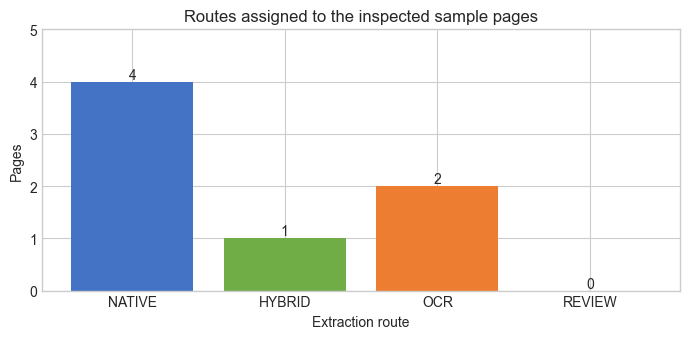

In [5]:
route_counts = routing_table["method"].value_counts().reindex(
    ["NATIVE", "HYBRID", "OCR", "REVIEW"], fill_value=0
)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(route_counts.index, route_counts.values, color=["#4472C4", "#70AD47", "#ED7D31", "#A5A5A5"])
ax.set_title("Routes assigned to the inspected sample pages")
ax.set_xlabel("Extraction route")
ax.set_ylabel("Pages")
ax.set_ylim(0, max(route_counts.values) + 1)
for position, count in enumerate(route_counts.values):
    ax.text(position, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Failure case

Page 65 contains a raster figure whose text is important, yet its image coverage falls below the scan threshold. The page is routed to `NATIVE`, demonstrating that the heuristic answers “how should the page text layer be extracted?” rather than “is every visible fact recoverable as text?”

In [6]:
routing_table.loc[routing_table["page_id"] == "ch2.pdf p.65"]

,page_id,native_words,image_count,largest_image_fraction,method
3,ch2.pdf p.65,39,2,0.807,NATIVE


## Validation — decision boundaries

In [7]:
boundary_cases = [
    ({"native_words": 0, "image_count": 1, "largest_image_fraction": 0.90}, "OCR"),
    ({"native_words": 19, "image_count": 1, "largest_image_fraction": 0.90}, "HYBRID"),
    ({"native_words": 20, "image_count": 1, "largest_image_fraction": 0.90}, "REVIEW"),
    ({"native_words": 1, "image_count": 0, "largest_image_fraction": 0.00}, "NATIVE"),
    ({"native_words": 0, "image_count": 0, "largest_image_fraction": 0.00}, "REVIEW"),
]

for features, expected in boundary_cases:
    observed = select_method(features)
    assert observed == expected, (features, expected, observed)

known_routes = dict(zip(routing_table["page_id"], routing_table["method"]))
assert known_routes["scanned.pdf p.1"] == "HYBRID"
assert known_routes["scanned.pdf p.2"] == "OCR"
assert known_routes["ch2.pdf p.9"] == "NATIVE"

print("Boundary cases and known-page routes are correct.")

Boundary cases and known-page routes are correct.


## Next step

`04_ocr_and_page_records.ipynb` executes each route, compares OCR modes, and builds the first inspectable page record.